### Exploratory Data Analysis
---
**EDA Objectives**

- To understand the behavior and distribution of target variable `No-show`.

- To analyze how frequently patients missed their appointment.

- What is the relation between time factors and the target variable.

- Is patient's medical history and economic factor influence their decision to go to the hospital on appointment day.

### Target Variable Analysis

In [1]:
import pandas as pd

df = pd.read_csv('../data/processed/medical_appointment_no_show_cleaned.csv')

In [2]:
df['No-show'].value_counts(normalize=True)*100

No-show
No     71.452712
Yes    28.547288
Name: proportion, dtype: float64

### Target Variable Distribution
---
- It can be observed that about 71% of patients showed up on the data of appointment.

- Approximately 29% of the total patients did not show up.

- This is a moderate class imbalance which will be considered at the time of model evaluation.

- It can be visualized with the help of bar plot.

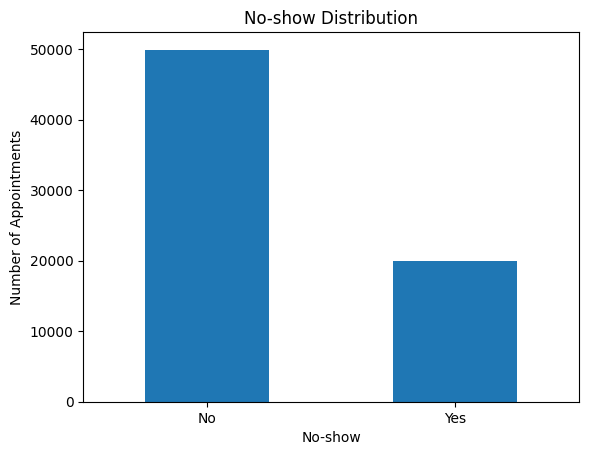

In [3]:
import matplotlib.pyplot as plt

df['No-show'].value_counts().plot(kind='bar')
plt.title('No-show Distribution')
plt.xlabel('No-show')
plt.xticks(rotation = 0)
plt.ylabel('Number of Appointments')
plt.show()


### Observation
---
- Majority of the Appointments approx 50k were attended by the patients.

- Around 20K appointments were missed.

- It clearly represents imbalanced distribution of target variable.

### Waiting Days Vs No-show
---
- The goal is to observe that what is the influence of waiting days over appointments attendance.

- It is likely to expect that long waiting days will result in more missed appointments.

In [4]:
df.groupby('No-show')['WaitingDays'].describe()

,count,mean,std,min,25%,50%,75%,max
No-show,,,,,,,,
No,49894.0,13.939572,16.423325,0.0,3.0,7.0,20.0,178.0
Yes,19934.0,16.172770,16.628302,0.0,4.0,12.0,24.0,178.0


### Observation
---
- It can be seen that the average of waiting days in case of missed appointments is more than the other.

- It is a strong predictor as it directly shows the relationship between 2 features
 

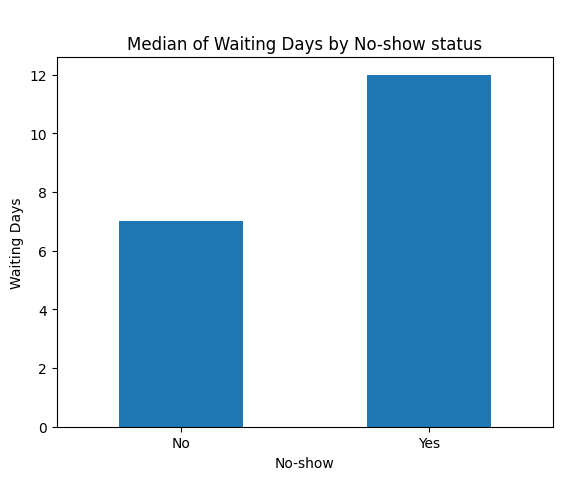

In [5]:
df.groupby('No-show')['WaitingDays'].median().plot(kind='bar')
plt.title('Median of Waiting Days by No-show status')
plt.suptitle(' ')
plt.xlabel('No-show')
plt.xticks(rotation = 0)
plt.ylabel('Waiting Days')
plt.show()

### Visualization Observation
---
- It can be simply observed that the difference between presence and absence on the appointment day is highly influenced by the waiting days.
- `Waiting Days` will play an important role in training the model while predicting the `No-show` feature.

### SMS_received Vs No-show
---
- It means that whether the patient received the message prior to their appointment or not.

- It is expected that the patients who were reminded before their appointment mostly do not miss appointment.

In [6]:
pd.crosstab(df['SMS_received'], df['No-show'], normalize='index')*100

No-show,No,Yes
SMS_received,,
0,70.587067,29.412933
1,72.334827,27.665173


### Observation
---
- A difference can be observed as around around `29%` of the patients missed appointments and do not recieved the SMS.

- On the other hand, around `27%` of the patients were absent on the appointment but thet recieved the message.


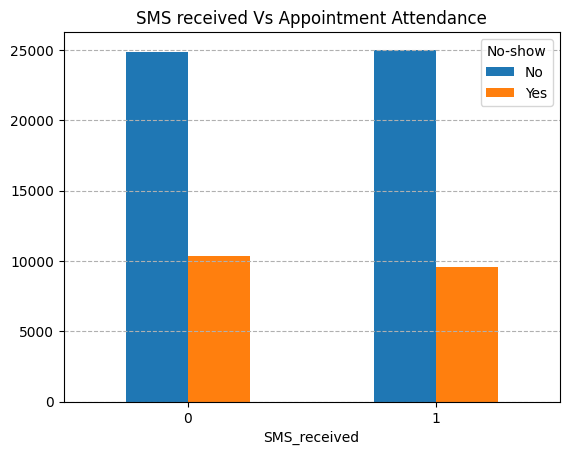

In [7]:
pd.crosstab(df['SMS_received'], df['No-show']).plot(kind='bar')
plt.title('SMS received Vs Appointment Attendance')
plt.xticks(rotation = 0)
plt.grid(linestyle = '--', axis='y')
plt.show()

### Visualization Observation
---
- The graph clearly shows a slight difference in the absentism of patients on the date of appointment.

- In case of recieving the sms as a reminder the number of patients who actually attended is a bit more than 10000.

- In contrast, around 9500 pateints were absent on the appointment day as well as do not recieved the reminder. 

### Patient's Medical History Vs No-show
---
- The goal is to see how patient's health records affect the No-show.

- 4 features in total which are `Hipertension`, `Diabetes`, `Alcoholism`, `Handcap_binary` are taken into account.

- All the features are binary.

In [8]:
medical_cols = ['Hipertension','Diabetes','Alcoholism','Handcap_binary']

for cols in medical_cols:
    print(cols)
    print(pd.crosstab(df[cols], df['No-show'], normalize='index')*100)
    print('-'*40)

Hipertension
No-show              No        Yes
Hipertension                      
0             70.074458  29.925542
1             76.476849  23.523151
----------------------------------------
Diabetes
No-show          No        Yes
Diabetes                      
0         71.153279  28.846721
1         75.041845  24.958155
----------------------------------------
Alcoholism
No-show            No        Yes
Alcoholism                      
0           71.601035  28.398965
1           65.916575  34.083425
----------------------------------------
Handcap_binary
No-show                No        Yes
Handcap_binary                      
0               71.395631  28.604369
1               74.445295  25.554705
----------------------------------------


### Observation
---
- Patients sufferening from `Hipertension` are `6%` more likely to come on the appointment day.

- Around `75%` of the patients who were suffering from `Diabetes` were present which is `4%` more than that of normal.

- It can be observed that `Alcoholic` patients are less likely to come on the day of appointment.

- There is `3%` increase in the patients presence on the day of appointment who are `Handicapped`. 

### Categorizing Age against No-show
---
- Evaluate appointment attendance patterns (presence vs. absence) by patient age group.

- Helps in identifying the age group which is most likely to be absent of the appointed day.


In [9]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins = [0,18,36,56,116],
    labels = ['Child', 'Young Adult','Adult','Senior']
)

pd.crosstab(df['AgeGroup'], df['No-show'], normalize = 'index')*100

No-show,No,Yes
AgeGroup,,
Child,66.794149,33.205851
Young Adult,66.007527,33.992473
Adult,72.721390,27.278610
Senior,78.917993,21.082007


### Observation
---
- `Child` and `Young Adult` mostly showed same result as approx `33%` of the patients of this group were absent.

- There is an effective increase in the presence of patients of `Adult` group as 72% patients attended the appointment.

- Lastly, `Senior` category of patients showed the highest percentage of patients who were presnt and that is about `79%`. 

## EDA Summary
---
- The target variable shows a noticeable percentage of patients who miss appointments, confirming this is a meaningful prediction problem.

- Waiting time appears to influence attendance — longer delays are associated with higher No-show behavior.

- Age shows variation in attendance patterns, indicating demographic influence on appointment behavior.

- Medical history features (Hypertension, Diabetes, Alcoholism, Handicap_binary) show some behavioral differences but are not individually dominant factors.

- SMS reminders show limited but observable impact, suggesting communication helps but does not fully prevent No-shows.